# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang, Lani Le, Yipeng Cao

**Date:** 11/9/2026

In [1]:
# import all the necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler


Shape: (16768, 19)
sale_date                      datetime64[us]
sale_price                              int64
house_square_feet                       int64
attic_finished_square_feet              int64
basement_square_feet                    int64
attached_garage_square_feet             int64
detached_garage_square_feet             int64
fireplaces                              int64
hvac_description                          str
exterior                                  str
interior                                  str
stories                                 int64
roof_cover                                str
year_built                              int64
bedrooms                                int64
bathrooms                               int64
waterfront_type                           str
view_quality                              str
utility_sewer                             str
dtype: object
waterfront_type                16216
view_quality                   15852
roof_cover         

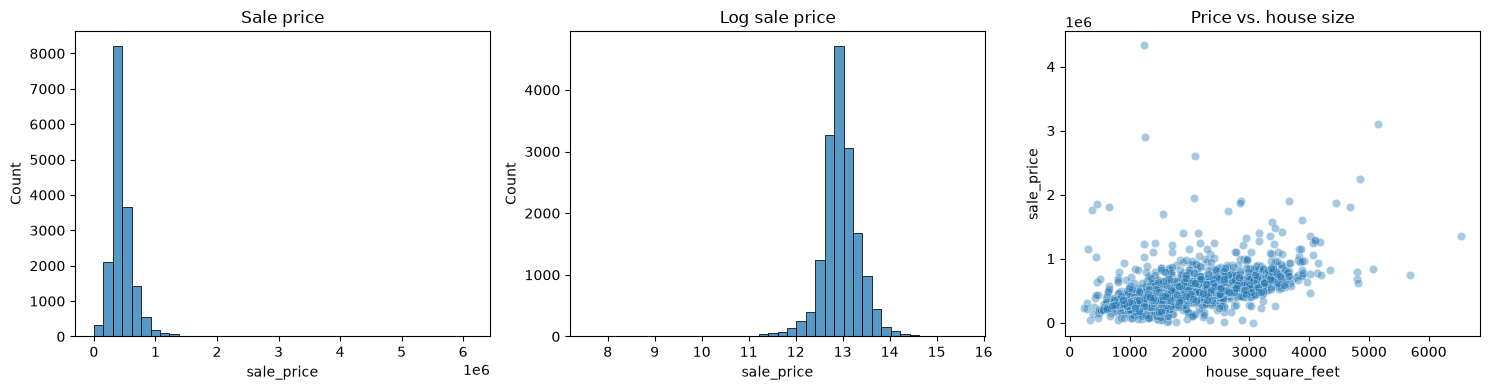

In [2]:
# 1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
df = pd.read_csv('data/pierce_county_house_sales.csv')
# make sale_date a datetime object
df["sale_date"] = pd.to_datetime(df["sale_date"], errors="coerce")
# drop dups
df = df.drop_duplicates()
df = df.dropna(subset=["sale_date"])
df = df[(df["sale_price"] > 0) & (df["house_square_feet"] > 0)].copy()

# print out the shape (16768, 19)
print("Shape:", df.shape)
print(df.dtypes)
print(df.isna().sum().sort_values(ascending=False))
print(df[["sale_price", "house_square_feet", "year_built",
          "bedrooms", "bathrooms"]].describe())

# plot figures to visualize the distribution of sale_price and log(sale_price) 
# and the relationship between house_square_feet and sale_price
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["sale_price"], bins=40, ax=axes[0])
axes[0].set_title("Sale price")
sns.histplot(np.log1p(df["sale_price"]), bins=40, ax=axes[1])
axes[1].set_title("Log sale price")
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=42),
                x="house_square_feet", y="sale_price", alpha=.4, ax=axes[2])
axes[2].set_title("Price vs. house size")
plt.tight_layout()
plt.show()



In [3]:
# 2. Transform your variables - particularly categorical ones - for use in your regression analysis.
target = "sale_price"
numeric = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
    "stories", "year_built", "bedrooms", "bathrooms"
]
categorical = [
    "hvac_description", "exterior", "interior", "roof_cover",
    "waterfront_type", "view_quality", "utility_sewer"
]

# changing categorical variables to have values 0 or 1
def make_preprocessor(nums, cats):

    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="Missing"),
            OneHotEncoder(handle_unknown="ignore")
        ), cats)
    ])


In [4]:
# 3. Implement an 80/20 train-test split. Put the test data aside.
X = df[numeric + categorical]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
) # 0.2 because we want 80/20

In [5]:
# 4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
specs = {
    "Numeric only": numeric,
    "Categorical only": categorical,
    "Both numeric and categorical": numeric + categorical,
}
models = {}
rows = []

# for each model spec, create a pipeline with a preprocessor and lm 
# fit the lm for each spec, train them, and 
# eventually calculate the metrics (rmse and r_squared) 
# for both train and test sets
for name, cols in specs.items():
    nums = [c for c in cols if c in numeric]
    cats = [c for c in cols if c in categorical]
    model = Pipeline([
        ("prep", make_preprocessor(nums, cats)),
        ("reg", LinearRegression())
    ])
    model.fit(X_train[cols], y_train)
    models[name] = model

    for split_name, x, actual in [
        ("Train", X_train[cols], y_train),
        ("Test", X_test[cols], y_test),
    ]:
        pred = model.predict(x)
        rows.append({
            "Model": name,
            "Split": split_name,
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred),
        })

simple_results = pd.DataFrame(rows)
print(simple_results.round(3))
print("Best simple model by test RMSE:",
      simple_results.query("Split == 'Test'").sort_values("RMSE").iloc[0]["Model"])


                          Model  Split        RMSE     R2
0                  Numeric only  Train  185345.196  0.401
1                  Numeric only   Test  170421.990  0.411
2              Categorical only  Train  192675.277  0.353
3              Categorical only   Test  185517.354  0.302
4  Both numeric and categorical  Train  161581.020  0.545
5  Both numeric and categorical   Test  155461.334  0.510
Best simple model by test RMSE: Both numeric and categorical


As we can see from the result, the best model is the one that combines both numeric and categorical values. This model has the highest R^2 (model explains variance well, in this case over 50%) and lowest RMSE (smaller average error).

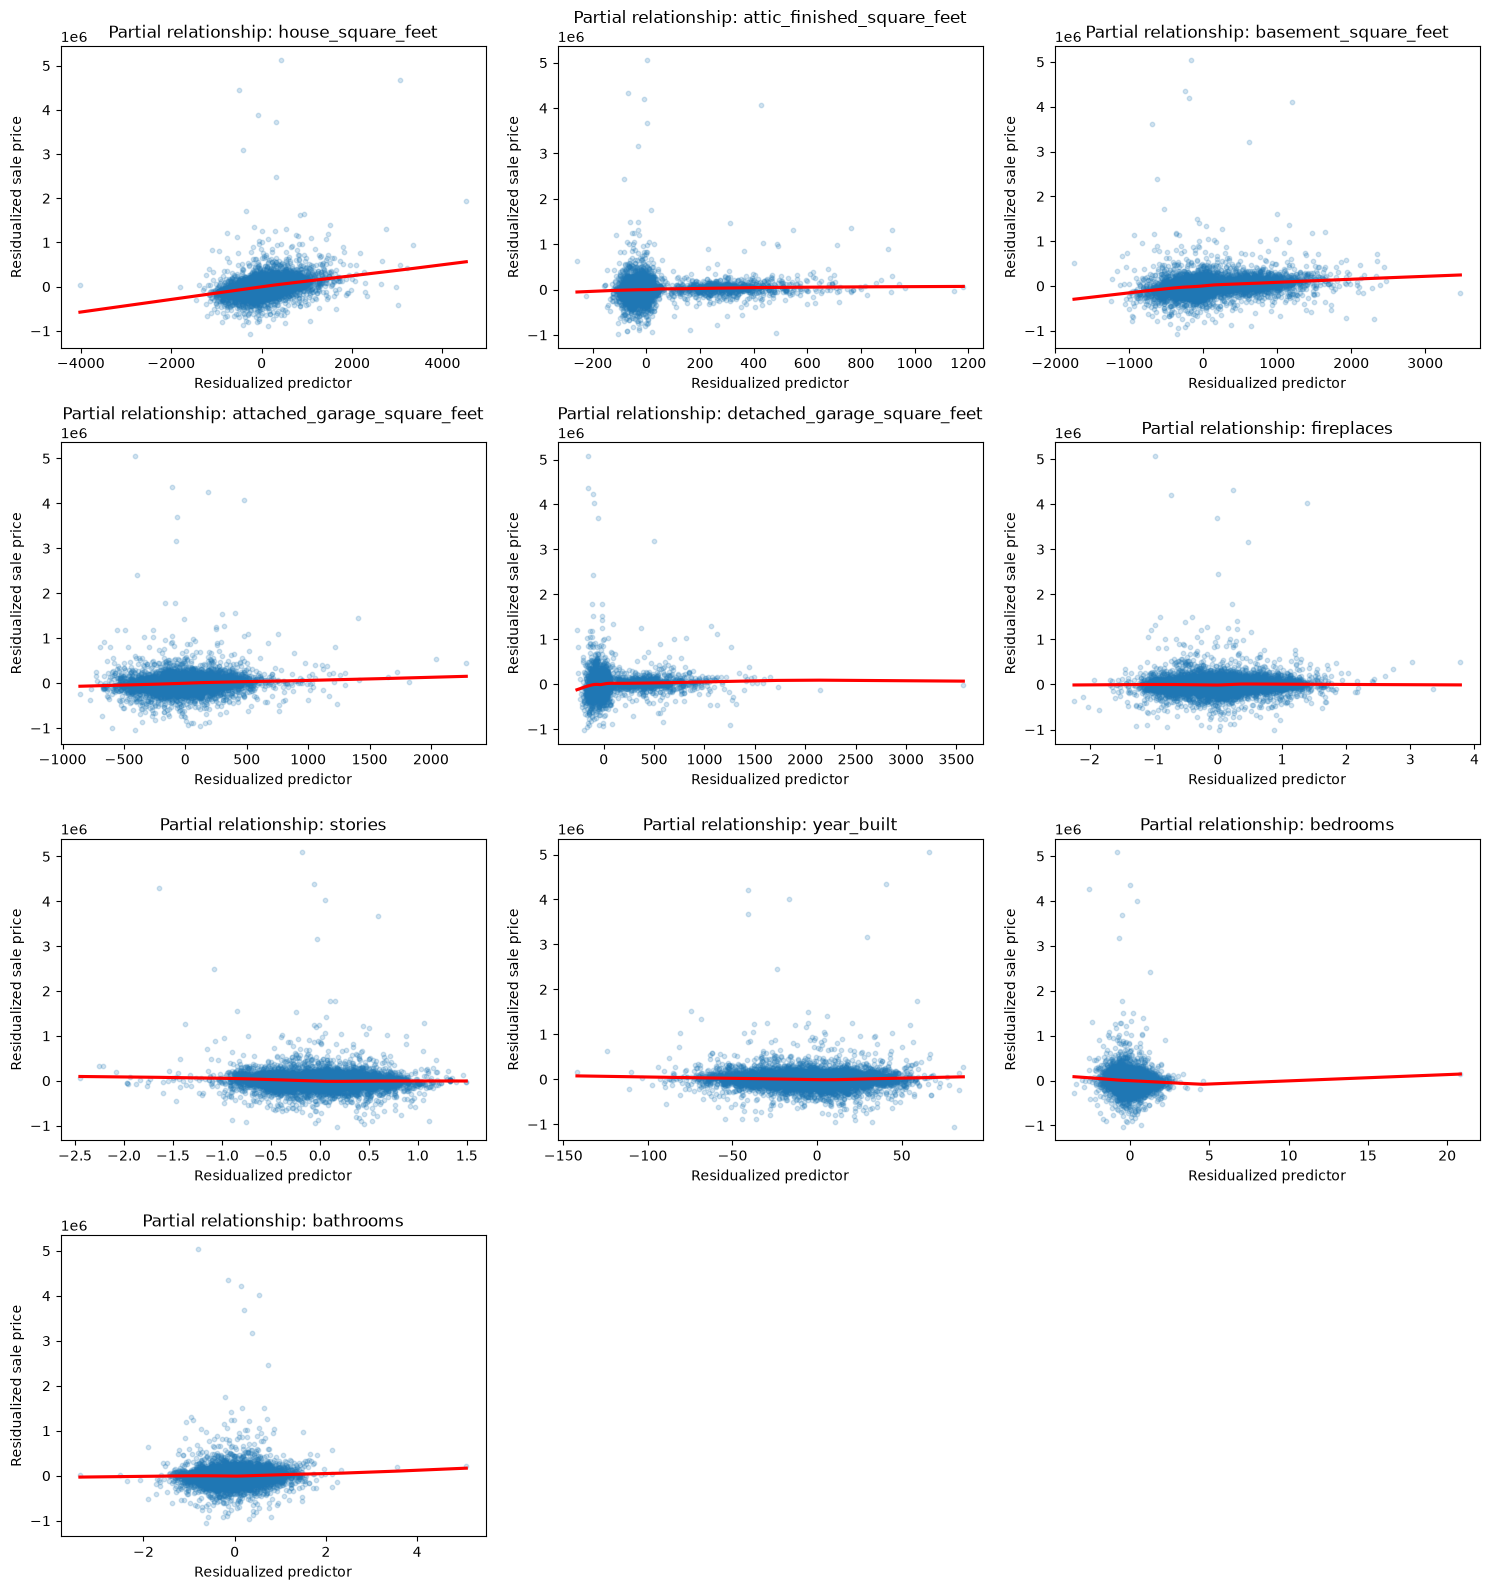

In [6]:
# 5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.ravel()

for i, feature in enumerate(numeric):
    controls = [c for c in numeric + categorical if c != feature]
    control_nums = [c for c in controls if c in numeric]
    control_cats = [c for c in controls if c in categorical]

    prep = make_preprocessor(control_nums, control_cats)
    Z = prep.fit_transform(X_train[controls])

    y_resid = y_train - LinearRegression().fit(Z, y_train).predict(Z)
    x_resid = X_train[feature] - LinearRegression().fit(
        Z, X_train[feature].fillna(X_train[feature].median())
    ).predict(Z)

    sns.regplot(x=x_resid, y=y_resid, lowess=True,
                scatter_kws={"alpha": .2, "s": 10},
                line_kws={"color": "red"}, ax=axes[i])
    axes[i].set_title(f"Partial relationship: {feature}")
    axes[i].set_xlabel("Residualized predictor")
    axes[i].set_ylabel("Residualized sale price")

for ax in axes[len(numeric):]:
    ax.remove()
plt.tight_layout()
plt.show()


There exists some non-linearities, such as attic finished_square_feet (most buyers probably do not care about if it is finished, so it shows little correlation), detached_garage_square_feet (most homes have 0 so it shows as non-linear), and bedrooms (Bedrooms may look nonlinear because bedroom count is discrete and overlaps with house size and bathrooms, while homes with unusually many bedrooms are rare).

In [7]:
# 6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
def add_engineered_features(frame):
    out = frame.copy()
    # break the date into yr, month
    out["sale_year"] = out["sale_date"].dt.year
    out["sale_month"] = out["sale_date"].dt.month
    # the house age is the difference between the sale year and the year built
    out["house_age"] = out["sale_year"] - out["year_built"]
    out["total_area"] = (
        out["house_square_feet"] + out["attic_finished_square_feet"]
        + out["basement_square_feet"]
    ) # create a new column of total area by summing the other cols
    out["total_garage_area"] = (
        out["attached_garage_square_feet"] + out["detached_garage_square_feet"]
    ) # total_garage
    return out.drop(columns="sale_date")

X_complex = add_engineered_features(df)
complex_numeric = numeric + [
    "sale_year", "sale_month", "house_age", "total_area", "total_garage_area"
]
complex_categorical = categorical
complex_cols = complex_numeric + complex_categorical

def make_complex_preprocessor():
    return ColumnTransformer([
        ("num", make_pipeline(
            SimpleImputer(strategy="median"),
            PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
        ), complex_numeric),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="Missing"),
            OneHotEncoder(handle_unknown="ignore")
        ), complex_categorical)
    ])

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_complex[complex_cols], y, test_size=0.20, random_state=42
)
complex_model = Pipeline([
    ("prep", make_complex_preprocessor()),
    ("reg", LinearRegression())
])
complex_model.fit(Xc_train, yc_train)

for split_name, x, actual in [
    ("Train", Xc_train, yc_train),
    ("Test", Xc_test, yc_test),
]:
    pred = complex_model.predict(x)
    print(f"Complex model {split_name}: "
          f"RMSE={np.sqrt(mean_squared_error(actual, pred)):.2f}, "
          f"R2={r2_score(actual, pred):.3f}")



Complex model Train: RMSE=175272.92, R2=0.464
Complex model Test: RMSE=162474.97, R2=0.464


We engineered additional features, including total house area, sale year and month, house age, and total garage area, and added pairwise interactions to build a more complex model. However, the complex model performed worse than the simple model with both numeric and categorical predictors: its test \(R^2\) fell from 0.510 to 0.464, and its test RMSE rose from about $155,461 to $162,475. This suggests that the added features and interactions did not improve predictions; because training performance also declined, the results do not indicate classic overfitting.

7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

After cleaning and exploring the data, I found that the dataset contains both numeric and categorical features, with much of the missing data in waterfront_type and view_quality. I one-hot encoded the categorical variables and used an 80/20 train-test split. The model with both numeric and categorical predictors performed best among the simple models, with a test RMSE of about $155,461 and test R^2 of 0.510. The partial regression plots looked mostly linear or weak; detached garage area showed some flattening, while the curve for bedrooms was less clear because few homes had high residualized bedroom counts. Adding engineered features and interactions did not improve performance: the complex model’s test RMSE increased to about $162,475 and its test R^2 fell to 0.464. The simple model had a modest train-test gap, but the results show no severe overfitting. They also show that adding complexity does not guarantee better predictions, so I would select the simpler model based on its stronger test performance.

In [10]:
# 8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.
from sklearn.linear_model import LassoCV

prep = complex_model.named_steps["prep"]
Xctr = prep.transform(Xc_train)
Xcte = prep.transform(Xc_test)

scaler = StandardScaler(with_mean=False)
Xctr_scaled = scaler.fit_transform(Xctr)
Xcte_scaled = scaler.transform(Xcte)

lasso = LassoCV(cv=5, max_iter=20000)
lasso.fit(Xctr_scaled, yc_train)

selected = pd.Series(
    lasso.coef_,
    index=prep.get_feature_names_out()
)
print(selected[selected.abs() > 1e-8].sort_values(key=abs, ascending=False))

pred = lasso.predict(Xcte_scaled)
print(
    f"Test RMSE: {np.sqrt(mean_squared_error(yc_test, pred)):.2f}, "
    f"R_squared: {r2_score(yc_test, pred):.3f}"
)

cat__waterfront_type_WF Salt                                   66542.086168
num__house_square_feet year_built                              60095.608737
num__fireplaces total_area                                     39550.855153
cat__waterfront_type_WF Lake                                   36052.619849
cat__exterior_Missing                                          34183.982195
                                                                   ...     
cat__waterfront_type_Missing                                    -470.574121
cat__view_quality_View Lim +                                     221.755313
num__fireplaces sale_month                                       119.243096
num__house_age total_area                                        -40.624950
num__attic_finished_square_feet detached_garage_square_feet       13.441331
Length: 92, dtype: float64
Test RMSE: 149503.82, R_squared: 0.547


## *Phase 2: AI-assisted Revision
Phase 1 above is preserved unchanged. Corrections and new analysis appear below.

- **Phase 1 commit SHA ID (student-provided):** c9b3142968c965b89a2f942662fb9618798eab18
- **AI tool and model used:** GPT 6.1 sol light

### *Prompts used

1. “Given the given problem prompts, check my current implementations for phase 2, correct or improve any parts we did in part 1"

2. "Give us specific implementation details"

### *AI-proposed changes

1. Preserve Phase 1 and reproduce the cleaning and fixed 80/20 split in an independent Phase 2 solution; flag questionable records without inventing exclusion thresholds.
2. Fit imputation, encoding, feature expansion, and scaling within each cross-validation training fold, and choose models using training-only cross-validation.
3. Recompute all simple-model metrics and partial regression plots; interpret residual patterns cautiously rather than treating sparsity or weak association as proof of nonlinearity.
4. Replace redundant totals and exhaustive unscaled interactions with scaled quadratic numeric terms, numeric interactions, and sale-month indicators; use the same rows for every model.
5. Tune sklearn.linear_model.Lasso in a complete pipeline, report both train and test metrics, and list every selected feature.
6. Compare cross-validation and held-out results, distinguish numerical instability from overfitting, document limitations, and reserve the required personal reflection for the students.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Phase 1 cells are unchanged; cleaned counts and questionable-record counts are printed below. |
| 2 | Accept | A fixed five-fold split is reused; GridSearchCV receives complete preprocessing pipelines and training rows only. |
| 3 | Accept | Metrics are recomputed and each numeric predictor is residualized against all other predictors using training data. |
| 4 | Modify | Use degree-two numeric features with sale month encoded categorically; omit redundant totals, age, and year to avoid exact dependencies. There is only one sale year in this dataset, verified below. |
| 5 | Accept | Lasso alpha is chosen using training CV; selected coefficients and both split metrics are reported. |
| 6 | Accept | The final table supplies comparable dollar-scale results; the personal reflection remains student-authored. |

### *AI-assisted solution in full


Matplotlib is building the font cache; this may take a moment.


Raw: 16,814; exact duplicate rows: 46; cleaned: 16,768
Sale years: [np.int32(2020)]
Flags retained for review: {'area_under_100': 1, 'zero_bedrooms': 47, 'zero_bathrooms': 31, 'built_after_sale': 45}


,Missing
sale_date,0
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
hvac_description,7
exterior,1


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00,16768.00
mean,461205.35,1879.17,25.01,168.19,364.22,38.37,0.89,1.56,1980.40,3.28,2.32
std,236115.78,760.44,102.20,429.46,286.65,164.88,0.60,0.51,33.33,0.89,0.83
min,2000.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1880.00,0.00,0.00
25%,348000.00,1320.00,0.00,0.00,0.00,0.00,1.00,1.00,1959.00,3.00,2.00
50%,416725.00,1774.00,0.00,0.00,420.00,0.00,1.00,2.00,1990.00,3.00,2.00
75%,523881.50,2351.25,0.00,0.00,528.00,0.00,1.00,2.00,2006.00,4.00,3.00
max,6130000.00,9510.00,1212.00,4000.00,2816.00,3664.00,5.00,3.00,2021.00,25.00,8.00


Train/test rows: 13414 3354


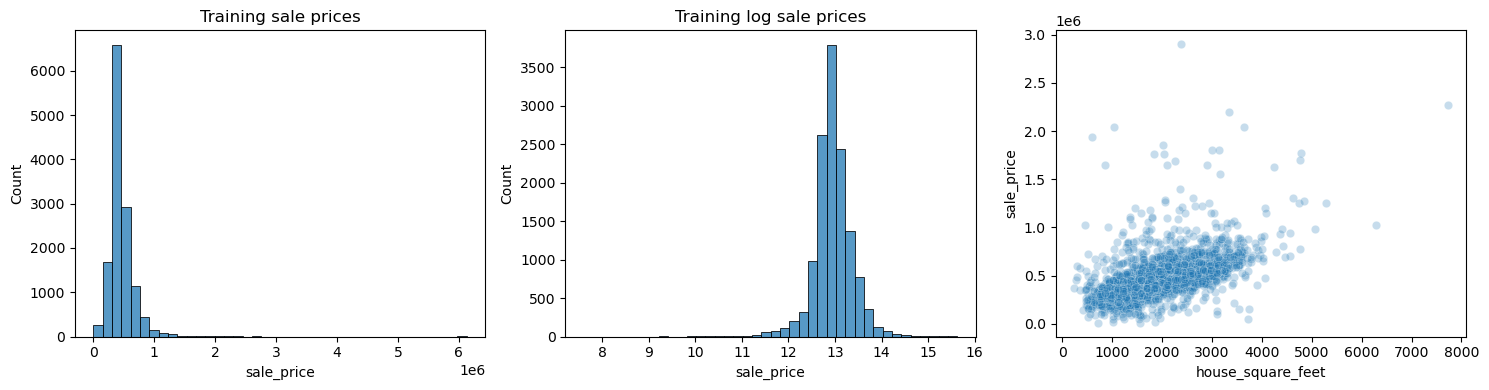

In [1]:
# 1–3. Imports, reproducible cleaning, EDA, and one shared train/test split.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

raw2 = pd.read_csv('data/pierce_county_house_sales.csv')
df2 = raw2.drop_duplicates().copy()
df2['sale_date'] = pd.to_datetime(df2['sale_date'], errors='coerce')
df2 = df2.dropna(subset=['sale_date', 'sale_price', 'house_square_feet'])
df2 = df2.loc[(df2.sale_price > 0) & (df2.house_square_feet > 0)].copy()
nums2 = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
         'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces',
         'stories', 'year_built', 'bedrooms', 'bathrooms']
cats2 = ['hvac_description', 'exterior', 'interior', 'roof_cover',
         'waterfront_type', 'view_quality', 'utility_sewer']
print(f'Raw: {len(raw2):,}; exact duplicate rows: {raw2.duplicated().sum():,}; cleaned: {len(df2):,}')
print('Sale years:', sorted(df2.sale_date.dt.year.unique()))
print('Flags retained for review:', {'area_under_100': int((df2.house_square_feet < 100).sum()),
      'zero_bedrooms': int((df2.bedrooms == 0).sum()),
      'zero_bathrooms': int((df2.bathrooms == 0).sum()),
      'built_after_sale': int((df2.year_built > df2.sale_date.dt.year).sum())})
display(df2.isna().sum().rename('Missing').to_frame())
display(df2[['sale_price'] + nums2].describe().round(2))
# Month extraction is deterministic; it learns nothing from the target or test set.
X2 = df2[nums2 + cats2].copy()
X2['sale_month'] = df2.sale_date.dt.month.astype(str)
y2 = df2.sale_price
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=.2, random_state=42)
assert set(X2_train.index).isdisjoint(X2_test.index)
print('Train/test rows:', len(X2_train), len(X2_test))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(y2_train, bins=40, ax=axes[0]); axes[0].set_title('Training sale prices')
sns.histplot(np.log(y2_train), bins=40, ax=axes[1]); axes[1].set_title('Training log sale prices')
sns.scatterplot(data=X2_train.assign(sale_price=y2_train).sample(min(3000, len(y2_train)), random_state=42),
                x='house_square_feet', y='sale_price', alpha=.25, ax=axes[2])
plt.tight_layout(); plt.show()


Exact duplicate rows and invalid dates or nonpositive prices/areas are removed as in Phase 1. Small positive prices, tiny homes, zero room counts, and future build dates need source verification; no arbitrary outlier cutoff is imposed. Missing waterfront/view labels are encoded as “Missing,” which does not assume that a missing label means no waterfront or no view. Full-data counts are an audit; plots and model development use training rows. The random split measures performance on similar sales, not future-year forecasting.

In [2]:
# 4. Simple models: stable dense least squares, with scaling for conditioning.
def prep2(nums, cats, quadratic=False):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if quadratic:
        # Center first, expand, then scale expanded terms for Lasso penalties.
        steps += [('center', StandardScaler()),
                  ('poly', PolynomialFeatures(degree=2, include_bias=False))]
    steps += [('scale', StandardScaler())]
    return ColumnTransformer([
        ('num', Pipeline(steps), nums),
        ('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='Missing'),
                             OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)), cats)
    ], sparse_threshold=0)

candidates2 = {
    'Numeric only': Pipeline([('prep', prep2(nums2, [])), ('reg', LinearRegression())]),
    'Categorical only': Pipeline([('prep', prep2([], cats2)), ('reg', LinearRegression())]),
    'Numeric + categorical': Pipeline([('prep', prep2(nums2, cats2)), ('reg', LinearRegression())]),
}
cv2 = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X2_train))
searches2 = {}
for name, pipeline in candidates2.items():
    search = GridSearchCV(pipeline, {}, cv=cv2, scoring='neg_root_mean_squared_error', n_jobs=1)
    searches2[name] = search.fit(X2_train, y2_train)
display(pd.DataFrame({'CV RMSE': {name: -s.best_score_ for name, s in searches2.items()}}).round(2))


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWa

/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,CV RMSE
Numeric only,183433.95
Categorical only,199545.60
Numeric + categorical,167886.81


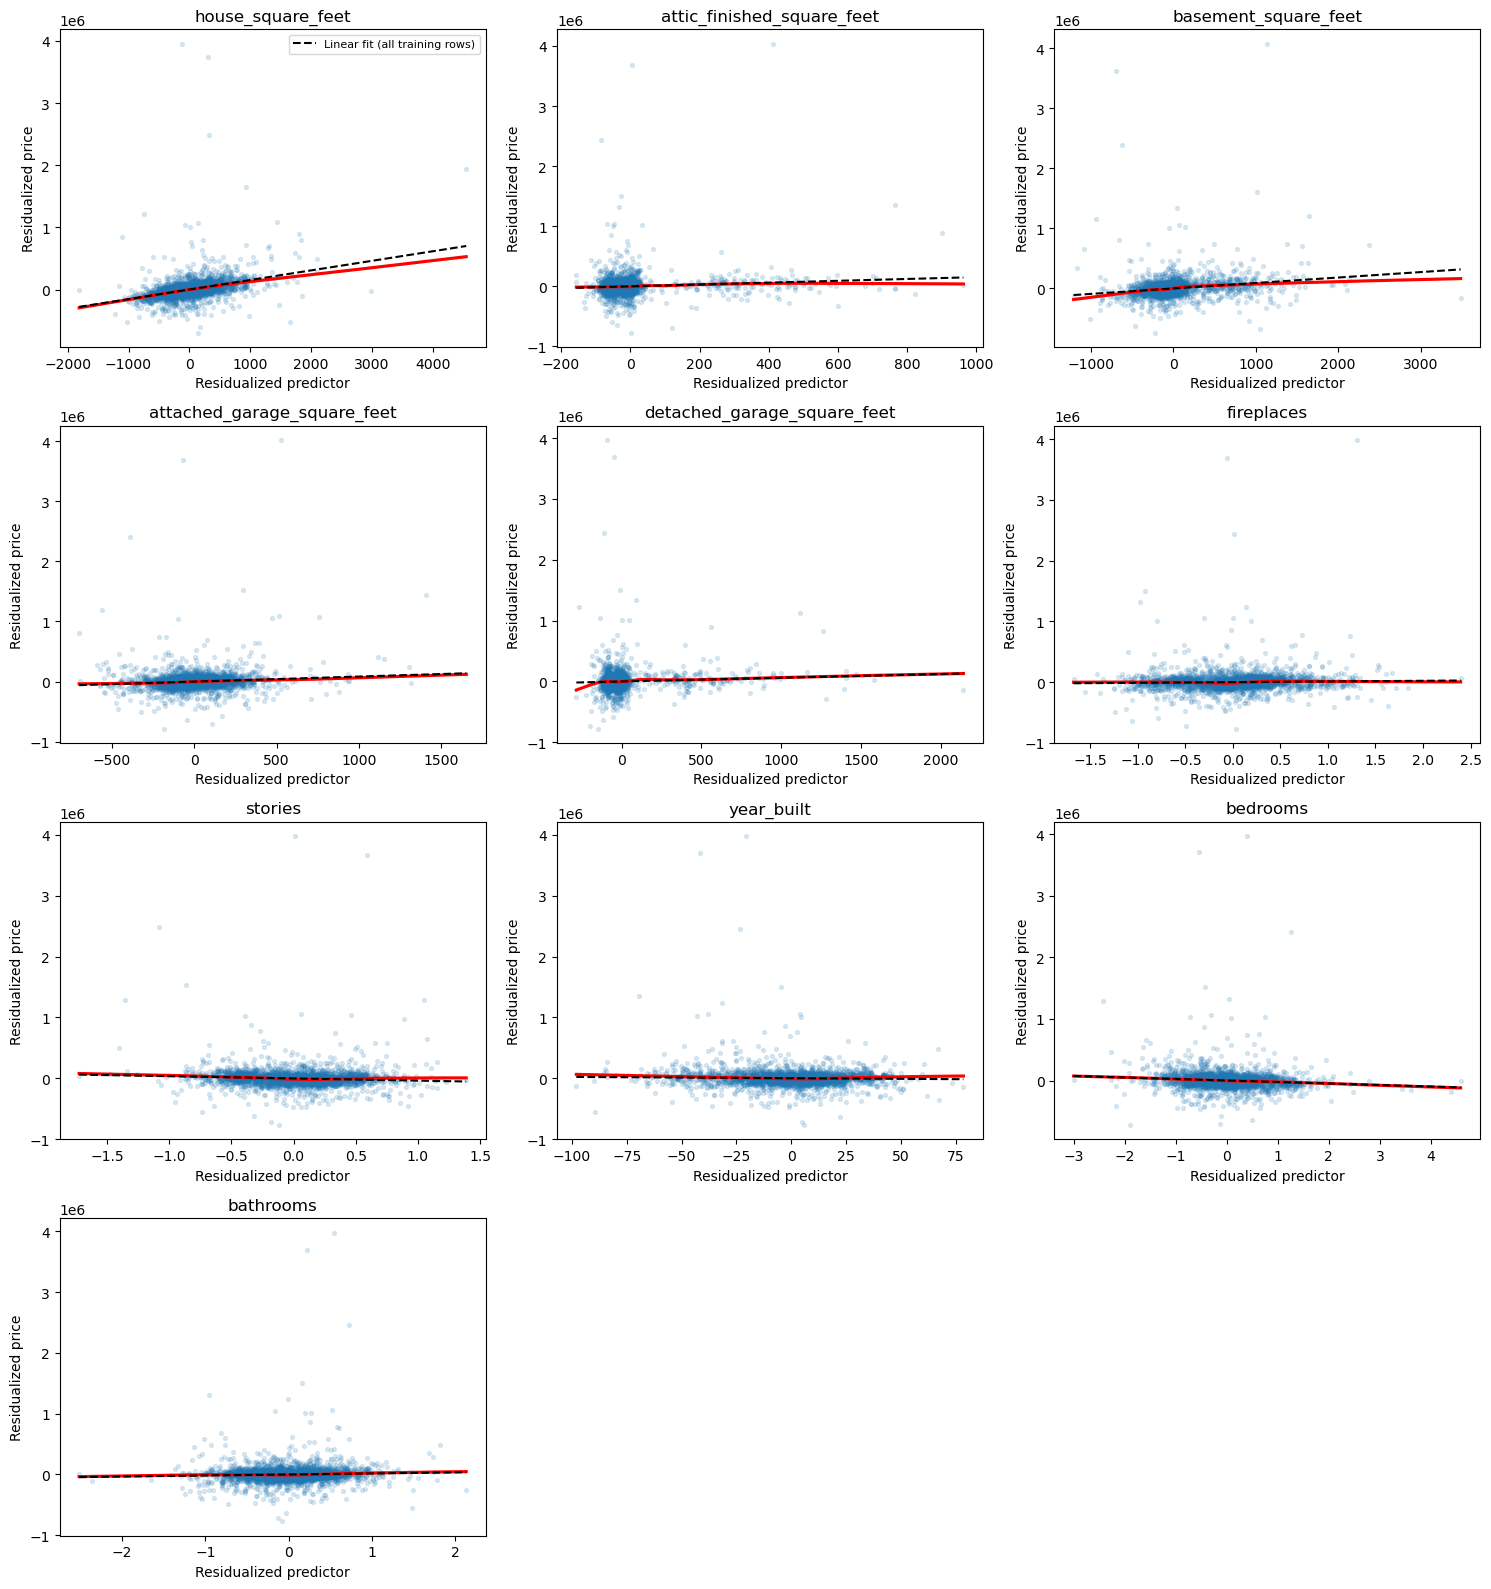

In [3]:
# 5. Added-variable (partial regression) plots on training observations only.
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, feature in zip(axes.ravel(), nums2):
    controls = [c for c in nums2 if c != feature]
    z = prep2(controls, cats2).fit_transform(X2_train)
    x = SimpleImputer(strategy='median').fit_transform(X2_train[[feature]]).ravel()
    xr = x - LinearRegression().fit(z, x).predict(z)
    yr = y2_train.to_numpy() - LinearRegression().fit(z, y2_train).predict(z)
    # A fixed sample makes LOWESS tractable; residual regressions use every training row.
    take = np.random.default_rng(42).choice(len(xr), min(2500, len(xr)), replace=False)
    sns.regplot(x=xr[take], y=yr[take], lowess=True, ax=ax,
                scatter_kws={'alpha': .15, 's': 8}, line_kws={'color': 'red'})
    slope = np.dot(xr, yr) / np.dot(xr, xr)
    xx = np.array([xr[take].min(), xr[take].max()])
    ax.plot(xx, slope * xx, '--', color='black', label='Linear fit (all training rows)')
    ax.set(title=feature, xlabel='Residualized predictor', ylabel='Residualized price')
for ax in axes.ravel()[len(nums2):]: ax.remove()
axes.ravel()[0].legend(fontsize=8)
plt.tight_layout(); plt.show()


The red smoother and dashed linear fit help diagnose departures from linearity conditional on the other predictors. Discrete room counts, many zero areas, and rare extreme observations can create unstable curves. Weak partial association is not evidence that buyers do not care about a feature. These are exploratory diagnostics, not significance tests or causal estimates. Quadratic area and room terms allow diminishing or increasing marginal effects; size–room and size–amenity interactions allow effects to vary with house characteristics.

In [4]:
# 6 and 8. Expanded OLS and regularized expanded regression.
# No summed areas (their definitions may overlap) or algebraically redundant age/year features.
complex2 = Pipeline([('prep', prep2(nums2, cats2 + ['sale_month'], quadratic=True)),
                     ('reg', LinearRegression())])
searches2['Quadratic + interactions'] = GridSearchCV(
    complex2, {}, cv=cv2, scoring='neg_root_mean_squared_error', n_jobs=1
).fit(X2_train, y2_train)
# GridSearchCV refits preprocessing within EVERY fold, unlike preprocessing before LassoCV.
lasso2 = Pipeline([('prep', prep2(nums2, cats2 + ['sale_month'], quadratic=True)),
                   ('scale_all', StandardScaler()),
                   ('reg', Lasso(max_iter=50000, tol=1e-4))])
searches2['Lasso expanded'] = GridSearchCV(
    lasso2, {'reg__alpha': np.logspace(1, 4, 10)}, cv=cv2,
    scoring='neg_root_mean_squared_error', n_jobs=1
).fit(X2_train, y2_train)
chosen2 = min(searches2, key=lambda name: -searches2[name].best_score_)
print('Model chosen by training CV:', chosen2)
print('Lasso selected alpha:', searches2['Lasso expanded'].best_params_['reg__alpha'])
assert searches2['Lasso expanded'].best_params_['reg__alpha'] not in (10., 10000.), 'Extend alpha grid: optimum on boundary'


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


... (13 outputs left out)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Model chosen by training CV: Lasso expanded
Lasso selected alpha: 1000.0


In [5]:
# Final evaluation: specifications and hyperparameters are now fixed.
results2 = []
for name, search in searches2.items():
    model = search.best_estimator_
    for split, xx, yy in [('Train', X2_train, y2_train), ('Test', X2_test, y2_test)]:
        pred = model.predict(xx)
        assert np.isfinite(pred).all()
        results2.append({'Model': name, 'Split': split,
                         'RMSE': np.sqrt(mean_squared_error(yy, pred)),
                         'R2': r2_score(yy, pred), 'CV RMSE': -search.best_score_})
results2 = pd.DataFrame(results2)
display(results2.round({'RMSE': 2, 'R2': 4, 'CV RMSE': 2}))
# Training-mean benchmark gives the scale of improvement.
print('Training-mean benchmark test RMSE:', round(np.sqrt(mean_squared_error(
    y2_test, np.repeat(y2_train.mean(), len(y2_test)))), 2))
fitted_lasso2 = searches2['Lasso expanded'].best_estimator_
coefs2 = pd.Series(fitted_lasso2.named_steps['reg'].coef_,
                   index=fitted_lasso2.named_steps['prep'].get_feature_names_out(), name='Coefficient')
selected2 = coefs2[coefs2.abs() > 1e-8].sort_values(key=abs, ascending=False)
print(f'Lasso retained {len(selected2)} / {len(coefs2)} encoded/expanded features:')
with pd.option_context('display.max_rows', None):
    display(selected2.to_frame().round(3))
print('Lasso iterations:', fitted_lasso2.named_steps['reg'].n_iter_)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Model,Split,RMSE,R2,CV RMSE
0,Numeric only,Train,185345.20,0.4011,183433.95
1,Numeric only,Test,170421.99,0.4108,183433.95
2,Categorical only,Train,192675.28,0.3528,199545.60
3,Categorical only,Test,185522.61,0.3017,199545.60
4,Numeric + categorical,Train,159882.23,0.5543,167886.81
5,Numeric + categorical,Test,154377.87,0.5165,167886.81
6,Quadratic + interactions,Train,151475.36,0.6000,164242.46
7,Quadratic + interactions,Test,149117.92,0.5489,164242.46
8,Lasso expanded,Train,152627.84,0.5939,161632.83
9,Lasso expanded,Test,149576.68,0.5461,161632.83


Training-mean benchmark test RMSE: 222050.04
Lasso retained 96 / 124 encoded/expanded features:


,Coefficient
num__house_square_feet,92215.589
cat__waterfront_type_WF Salt,65590.808
num__basement_square_feet,37549.031
cat__waterfront_type_WF Lake,35870.672
cat__exterior_Missing,32336.894
cat__exterior_Log,17869.134
num__attached_garage_square_feet,17707.208
num__bedrooms,-16339.808
num__house_square_feet^2,15773.126
num__house_square_feet year_built,15139.853


Lasso iterations: 57


In [6]:
# 7. Results-based summary, generated from the fitted models rather than copied numbers.
from IPython.display import Markdown
best_simple2 = min(candidates2, key=lambda name: -searches2[name].best_score_)
def metric2(name, split):
    return results2.loc[(results2.Model == name) & (results2.Split == split)].iloc[0]
s = metric2(best_simple2, 'Test'); c = metric2('Quadratic + interactions', 'Test')
l = metric2('Lasso expanded', 'Test'); winner = metric2(chosen2, 'Test')
display(Markdown(f"""**Summary.** The best simple specification by training CV is **{best_simple2}**:
held-out RMSE **${s.RMSE:,.0f}**, R² **{s.R2:.3f}**. The expanded OLS model has test RMSE
**${c.RMSE:,.0f}**, R² **{c.R2:.3f}**. Lasso retains **{len(selected2)} of {len(coefs2)}**
expanded/encoded features and has test RMSE **${l.RMSE:,.0f}**, R² **{l.R2:.3f}**.
The model selected before inspecting the test outcomes is **{chosen2}**, with held-out RMSE
**${winner.RMSE:,.0f}** and R² **{winner.R2:.3f}**.

Compare each model's train error with its CV and test errors: a lower training error accompanied
by worse validation error indicates overfitting; weak training and validation performance can
indicate underfitting or missing predictors. The quadratic model contains the simple model's
terms, so its training least-squares error should not increase beyond numerical tolerance.
The Phase 1 increase in training error therefore warrants checking numerical conditioning and
solver convergence rather than concluding that added features inherently hurt the training fit.
Scaling here improves conditioning without changing the simple linear model's intended function class.

Lasso coefficients refer to scaled, encoded features and the displayed reference categories;
nonzero coefficients are predictive selections, not causal effects or proof of statistical significance.
Correlated terms can substitute for one another. Heavy price tails and the lack of explicit
location features limit accuracy; RMSE is particularly sensitive to expensive sales.
This test set was already inspected in Phase 1, so it is not a fresh untouched confirmation set
for the overall assignment. Training-only CV reduces further selection bias, but a new dataset
would be needed for independent confirmation.
"""))
assert metric2('Quadratic + interactions', 'Train').RMSE <= metric2('Numeric + categorical', 'Train').RMSE + .01


**Summary.** The best simple specification by training CV is **Numeric + categorical**:
held-out RMSE **$154,378**, R² **0.517**. The expanded OLS model has test RMSE
**$149,118**, R² **0.549**. Lasso retains **96 of 124**
expanded/encoded features and has test RMSE **$149,577**, R² **0.546**.
The model selected before inspecting the test outcomes is **Lasso expanded**, with held-out RMSE
**$149,577** and R² **0.546**.

Compare each model's train error with its CV and test errors: a lower training error accompanied
by worse validation error indicates overfitting; weak training and validation performance can
indicate underfitting or missing predictors. The quadratic model contains the simple model's
terms, so its training least-squares error should not increase beyond numerical tolerance.
The Phase 1 increase in training error therefore warrants checking numerical conditioning and
solver convergence rather than concluding that added features inherently hurt the training fit.
Scaling here improves conditioning without changing the simple linear model's intended function class.

Lasso coefficients refer to scaled, encoded features and the displayed reference categories;
nonzero coefficients are predictive selections, not causal effects or proof of statistical significance.
Correlated terms can substitute for one another. Heavy price tails and the lack of explicit
location features limit accuracy; RMSE is particularly sensitive to expensive sales.
This test set was already inspected in Phase 1, so it is not a fresh untouched confirmation set
for the overall assignment. Training-only CV reduces further selection bias, but a new dataset
would be needed for independent confirmation.


### *Reflection on AI assistance
I use AI as a tool to make my coding process faster and more efficient. It helps me debug errors, understand unfamiliar code, and come up with different approaches to solving problems. When working on larger projects, I often use AI to explain complex functions, generate test cases, and suggest ways to improve my code. It is especially useful when I encounter a new programming language, framework, or library that I am not familiar with. AI also saves me time on repetitive tasks, allowing me to focus more on the overall design and logic of my projects. However, I understand that AI does not always provide correct answers, so I make sure to review, test, and understand the code before using it. I believe AI works best as a coding assistant rather than a replacement for programming skills. Overall, it has helped me become a more productive and confident programmer.

AI is quite good at making visual graphs and catching edge cases.